# RQ3 - What moves the Pell / non-Pell completion gap?

**Question.** Which institutions close the graduation-rate gap between
Pell-recipient students and everyone else?

**Design.** Year fixed effects, clustered SEs. Institution fixed effects are
*not* used here: the gap is only observed from 2015, and absorbing an
institution mean over so short a window leaves almost nothing to explain.

**Sample.** Four-year institutions, 2015-2021.

**Two decisions worth knowing about.**

1. The non-Pell rate is rebuilt from *counts* (completers / cohort) across the
   two non-Pell categories, not averaged from their two published rates - so a
   group of 400 does not get the same weight as a group of 12.
2. Institution-years with fewer than 30 students in either group are dropped.
   Without that filter, 55 institution-years show a "gap" of exactly 1.00
   because a cohort of three split perfectly. That is noise, not inequity.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import pandas as pd
from src import panels
from src.regression import panel_ols
pd.set_option("display.width", 120)

In [2]:
p, sector_cols = panels.sector_dummies(panels.rq3())
print(f"{len(p):,} institution-years, {p.unitid.nunique():,} institutions, {p.year.min()}-{p.year.max()}")
p[["pell_gap", "grad_rate_pell", "grad_rate_nonpell", "pct_pell", "cohort"]].describe().round(3)

12,034 institution-years, 2,009 institutions, 2015-2021


,pell_gap,grad_rate_pell,grad_rate_nonpell,pct_pell,cohort
count,12034.000,12034.000,12034.000,12034.000,12034.000
mean,0.084,0.487,0.572,0.368,1002.088
std,0.110,0.197,0.189,0.161,1436.579
min,-1.000,0.000,0.000,0.000,60.000
25%,0.034,0.344,0.448,0.250,276.000
50%,0.087,0.477,0.585,0.350,519.000
75%,0.142,0.615,0.707,0.450,1159.000
max,0.895,1.000,1.000,1.000,53387.000


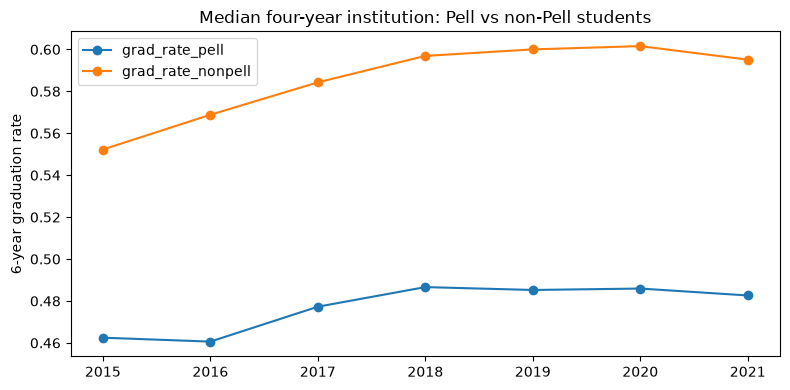

median gap by year (percentage points):
year
2015    7.5
2016    8.8
2017    8.9
2018    9.1
2019    8.7
2020    8.8
2021    8.9


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
p.groupby("year")[["grad_rate_pell", "grad_rate_nonpell"]].median().plot(ax=ax, marker="o")
ax.set(ylabel="6-year graduation rate", xlabel="",
       title="Median four-year institution: Pell vs non-Pell students")
plt.tight_layout(); plt.show()

print("median gap by year (percentage points):")
print((p.groupby("year").pell_gap.median() * 100).round(1).to_string())

In [4]:
res = panel_ols(p, "pell_gap", ["pct_pell", "log_avg_pell", "log_cohort"] + sector_cols,
                entity_effects=False, name="RQ3")
print(res.summary())

RQ3: 12,034 obs, 2,009 institutions, within R2=-0.004
                coef  stderr   tstat  pvalue  ci_low  ci_high
pct_pell     -0.0314  0.0137 -2.2831  0.0224 -0.0583  -0.0044
log_avg_pell -0.0537  0.0185 -2.9088  0.0036 -0.0898  -0.0175
log_cohort   -0.0024  0.0020 -1.2053  0.2281 -0.0062   0.0015
sector_2     -0.0061  0.0037 -1.6449  0.1000 -0.0134   0.0012
sector_3     -0.0510  0.0098 -5.1867  0.0000 -0.0703  -0.0317


A negative coefficient means the gap is *smaller* where that variable is
larger. `pct_pell` is the share of undergraduates receiving Pell: if it is
negative, institutions that serve many Pell students tend to have narrower
gaps - often because their non-Pell students are not that different from
their Pell students.

That is an association across institutions in the same year, not a causal
effect of enrolling more Pell students.

## Optional: add the finance controls, and watch the panel shrink

In [5]:
short = panels.rq3(with_finance=True)
print(f"with finance: {len(short):,} rows, {short.year.min()}-{short.year.max()}")
print(f"without:      {len(panels.rq3()):,} rows, 2015-2021")
# finance stops in 2017 and the gap starts in 2015, so endowment and
# student-services controls cost four of the seven years.

with finance: 5,272 rows, 2015-2017


without:      12,034 rows, 2015-2021


In [6]:
for f in panels.save(p, "rq3_panel"):
    print(f)

results/rq3_panel.parquet
results/rq3_panel.csv
results/rq3_panel.dta
